<a href="https://colab.research.google.com/github/UH-RMDS-DataChallenge-2026/data-science-challenge/blob/main/individual_work/24072989.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Town A — EDA, Random Forest and CatBoost

One Colab notebook with **EDA plots**, a shared stratified validation split, **Random Forest** and **CatBoost** model training, validation plots, and a side-by-side comparison. Run from top to bottom. The models save separate probability files to the same Google Drive project folder for later cost optimisation.



In [4]:
# Connect Drive and locate shared project files. Every notebook uses the same folder.
from google.colab import drive
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

drive.mount('/content/drive')
BASE = Path('/content/drive/MyDrive/Hackathon2026')
DATA, RESULTS, FIGURES, SUBMISSIONS = [BASE / x for x in ('data','results','figures','submissions')]
for folder in (DATA, RESULTS, FIGURES, SUBMISSIONS): folder.mkdir(parents=True,exist_ok=True)
sns.set_theme(style='whitegrid')
print('Project folder:',BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/Hackathon2026


In [5]:
# Upload the three original CSVs once through Colab's Files sidebar (/content).
# Also supports the filenames without the " (1)" suffix.
def find_csv(stem):
    candidates=[Path('/content')/(stem+'.csv'),Path('/content')/(stem+' (1).csv'),DATA/(stem+'.csv')]
    for p in candidates:
        if p.exists():return p
    raise FileNotFoundError(f'Missing {stem}.csv: upload it to the Colab Files sidebar')
train=pd.read_csv(find_csv('dataset_A_training'))
test=pd.read_csv(find_csv('dataset_A_testing'))
sample=pd.read_csv(find_csv('dataset_A_example_submission'))
print('Train:',train.shape,'Test:',test.shape,'Submission template:',sample.shape)
display(train.head())

Train: (4756, 31) Test: (4749, 30) Submission template: (4749, 2)


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


In [6]:
# Data integrity and descriptive statistics
assert train.respondent_id.is_unique and test.respondent_id.is_unique
assert set(train.respondent_id).isdisjoint(set(test.respondent_id))
assert train.seasonal_vaccine.notna().all()
assert set(train.seasonal_vaccine.unique()).issubset({0,1})
assert set(train.columns)-{'seasonal_vaccine'}==set(test.columns)
assert set(sample.respondent_id)==set(test.respondent_id)
print('Duplicate full rows:',train.duplicated().sum())
display(train.describe(include='all').T)

Duplicate full rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
flu_concern,4744.0,NaN,NaN,NaN,1.643128,0.91981,0.0,1.0,2.0,2.0,3.0
flu_knowledge,4733.0,NaN,NaN,NaN,1.293049,0.618902,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.052299,0.222652,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4724.0,NaN,NaN,NaN,0.734124,0.441846,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4753.0,NaN,NaN,NaN,0.073848,0.261551,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,NaN,NaN,NaN,0.836563,0.369803,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,NaN,NaN,NaN,0.365494,0.481619,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4747.0,NaN,NaN,NaN,0.336634,0.472608,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4737.0,NaN,NaN,NaN,0.68841,0.463192,0.0,0.0,1.0,1.0,1.0


## Page 1 — Data quality and missingness
**Analysis prompt:** Which variables have the highest missingness, and is missingness similar in the test set?

,Training %,Testing %
employment_sector,48.65,50.64
health_insurance,40.48,41.74
income_poverty,16.61,16.78
rent_or_own,8.01,7.98
doctor_recc_seasonal,6.75,7.26
education,5.68,5.66
employment_status,5.66,5.83
marital_status,5.57,5.66
child_under_6_months,3.20,3.26
health_worker,3.13,3.14


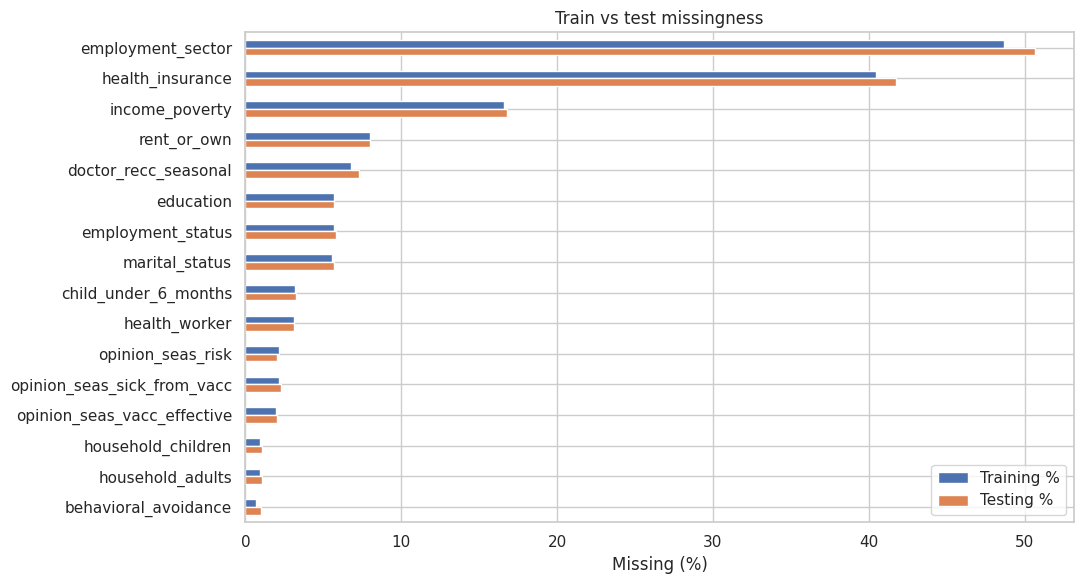

Interpretation: inspect large differences; fit imputers only on training data.


In [7]:
miss=pd.DataFrame({'Training %':train.drop(columns='seasonal_vaccine').isna().mean()*100,
                   'Testing %':test.isna().mean()*100}).sort_values('Training %',ascending=False)
display(miss.head(20).round(2))
fig,ax=plt.subplots(figsize=(11,6));miss.head(16).plot(kind='barh',ax=ax)
ax.invert_yaxis();ax.set_xlabel('Missing (%)');ax.set_title('Train vs test missingness');plt.tight_layout()
fig.savefig(FIGURES/'01_missingness.png',dpi=150);plt.show()
print('Interpretation: inspect large differences; fit imputers only on training data.')

## Page 2 — Target distribution and demographics

Vaccinated: 2551 Not vaccinated: 2205 Acceptance %: 53.64


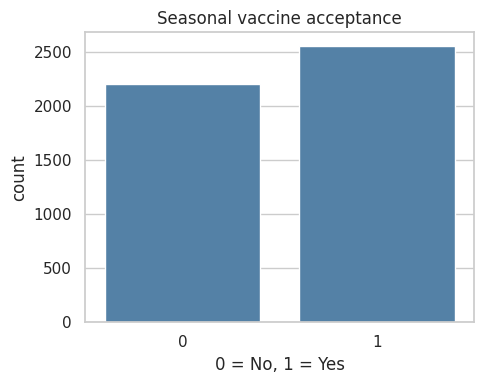

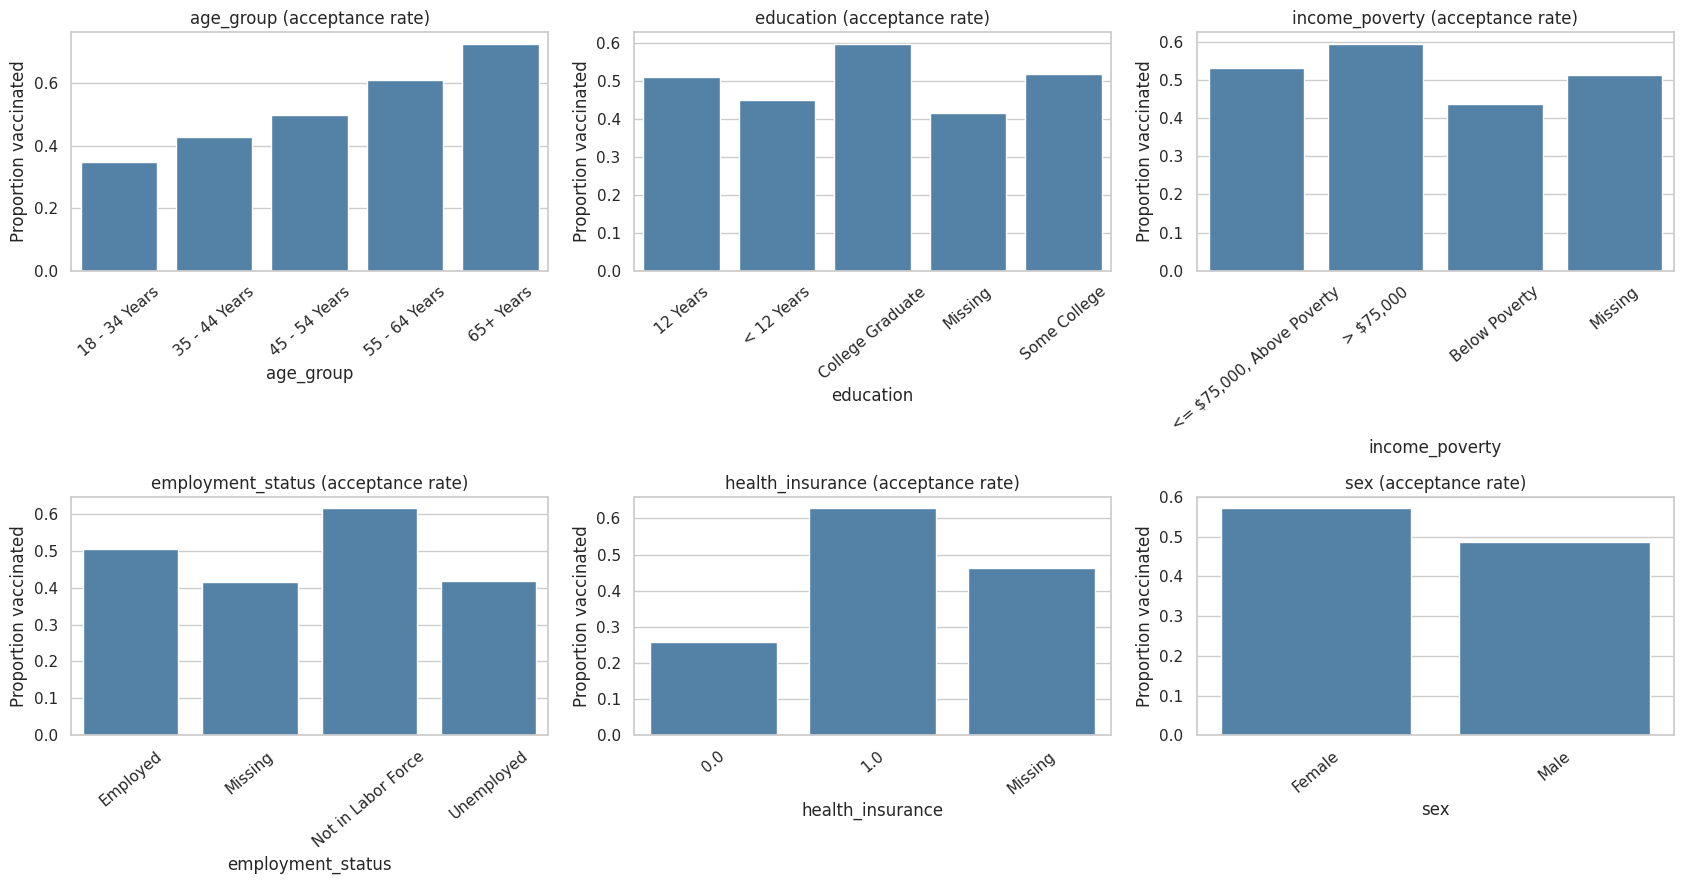

In [8]:
counts=train.seasonal_vaccine.value_counts().sort_index()
print('Vaccinated:',counts.get(1,0),'Not vaccinated:',counts.get(0,0),'Acceptance %:',round(train.seasonal_vaccine.mean()*100,2))
fig,ax=plt.subplots(figsize=(5,4));sns.countplot(data=train,x='seasonal_vaccine',ax=ax,color='steelblue')
ax.set_title('Seasonal vaccine acceptance');ax.set_xlabel('0 = No, 1 = Yes');plt.tight_layout()
fig.savefig(FIGURES/'02_target.png',dpi=150);plt.show()
features=['age_group','education','income_poverty','employment_status','health_insurance','sex']
fig,axs=plt.subplots(2,3,figsize=(17,9))
for feature,ax in zip(features,axs.flat):
    tmp=train[[feature,'seasonal_vaccine']].copy()
    tmp[feature]=tmp[feature].astype('string').fillna('Missing')
    rates=tmp.groupby(feature).seasonal_vaccine.agg(['mean','count']).reset_index()
    sns.barplot(data=rates,x=feature,y='mean',ax=ax,color='steelblue')
    ax.set_title(feature+' (acceptance rate)');ax.set_ylabel('Proportion vaccinated');ax.tick_params(axis='x',rotation=40)
plt.tight_layout();fig.savefig(FIGURES/'03_demographics.png',dpi=140);plt.show()

## Page 3 — Health factors and vaccine attitudes

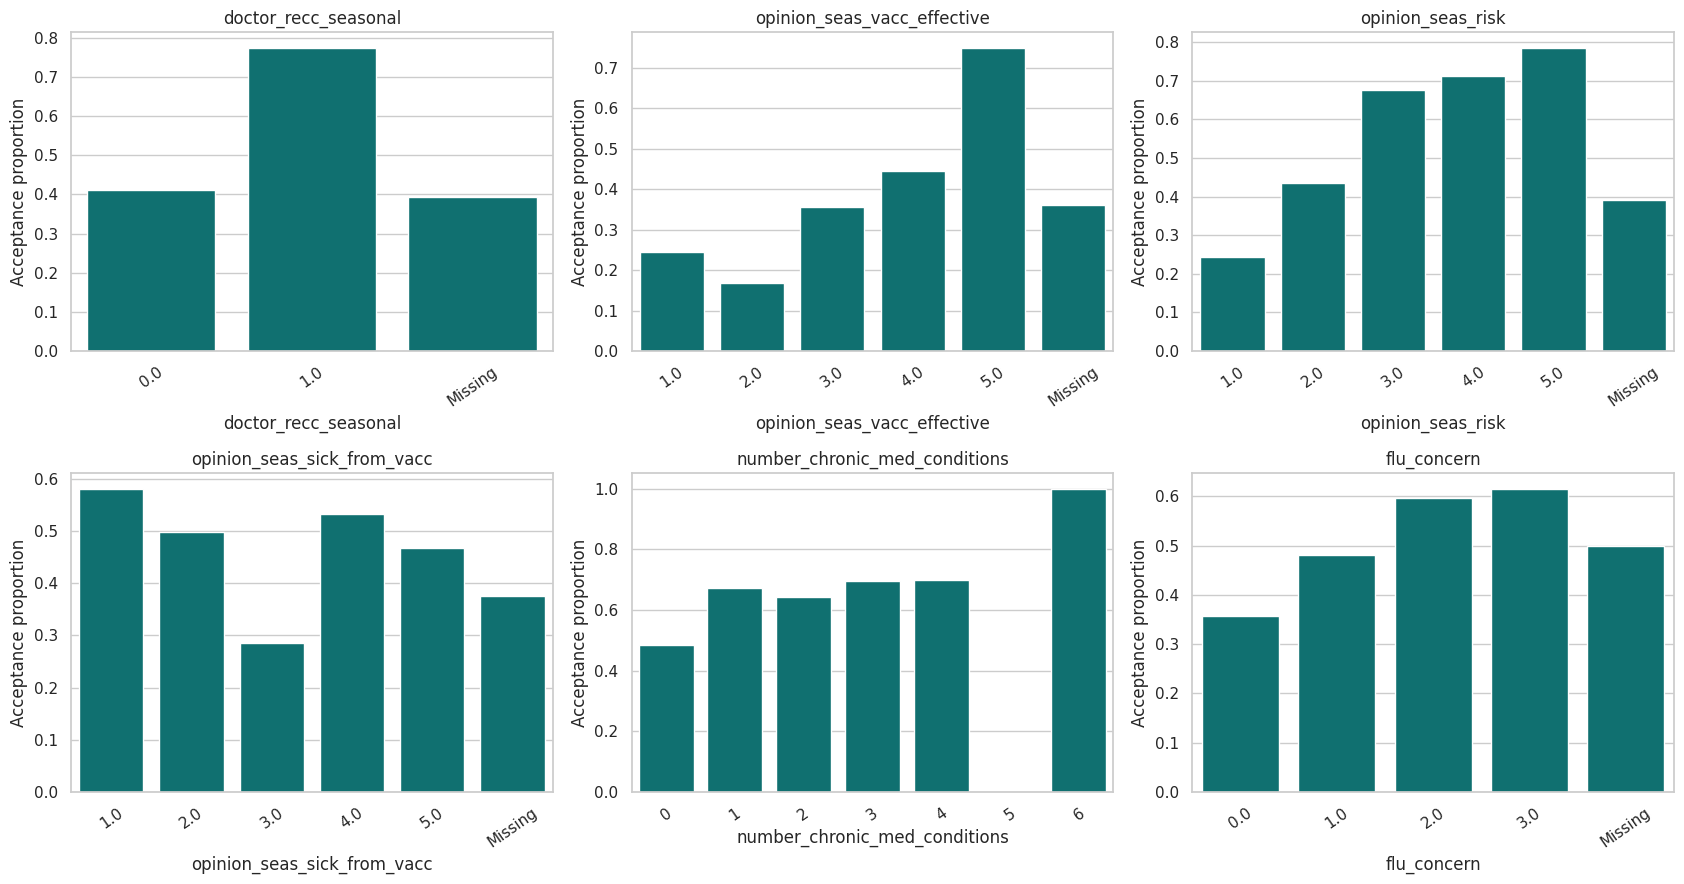

In [9]:
cols=['doctor_recc_seasonal','opinion_seas_vacc_effective','opinion_seas_risk',
      'opinion_seas_sick_from_vacc','number_chronic_med_conditions','flu_concern']
fig,axs=plt.subplots(2,3,figsize=(17,9))
for col,ax in zip(cols,axs.flat):
    tmp=train[[col,'seasonal_vaccine']].copy()
    tmp[col]=tmp[col].astype('string').fillna('Missing')
    rate=tmp.groupby(col).seasonal_vaccine.mean().reset_index()
    sns.barplot(data=rate,x=col,y='seasonal_vaccine',ax=ax,color='teal')
    ax.set_title(col);ax.set_ylabel('Acceptance proportion');ax.tick_params(axis='x',rotation=35)
plt.tight_layout();fig.savefig(FIGURES/'04_health_attitudes.png',dpi=140);plt.show()

## Page 4 — Age × chronic conditions and subgroup reliability

Acceptance %


number_chronic_med_conditions,0,1,2,3,4,5,6
age_group,,,,,,,
18 - 34 Years,32.6,48.0,40.7,50.0,0.0,NaN,NaN
35 - 44 Years,38.9,53.4,66.7,60.0,100.0,NaN,100.0
45 - 54 Years,45.8,63.3,56.8,60.0,50.0,NaN,NaN
55 - 64 Years,56.6,69.7,67.6,66.7,50.0,0.0,NaN
65+ Years,69.3,77.7,70.8,82.6,100.0,NaN,NaN


Subgroup counts


number_chronic_med_conditions,0,1,2,3,4,5,6
age_group,,,,,,,
18 - 34 Years,803,123,27,6,1,0,0
35 - 44 Years,548,118,24,5,1,0,1
45 - 54 Years,705,177,37,10,2,0,0
55 - 64 Years,652,261,71,12,2,1,0
65+ Years,668,385,89,23,4,0,0


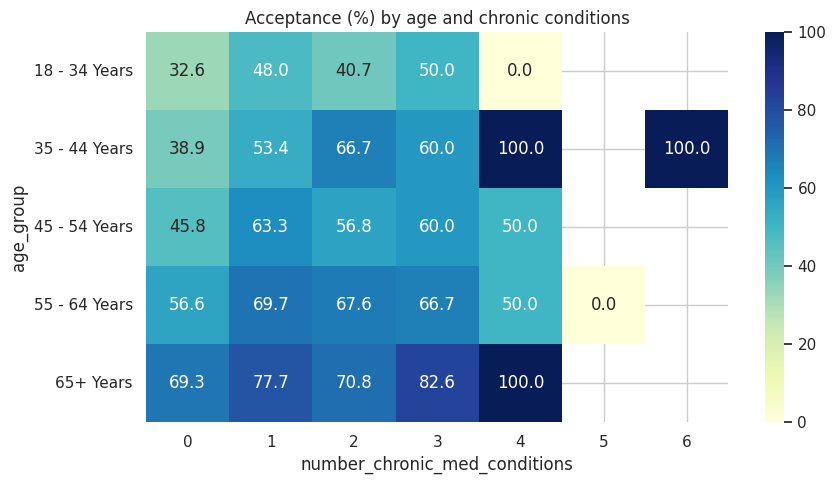

CAUTION: Small subgroups can produce unstable rates; check the count table.


In [10]:
rate=train.pivot_table(index='age_group',columns='number_chronic_med_conditions',values='seasonal_vaccine',aggfunc='mean')*100
n_group=train.pivot_table(index='age_group',columns='number_chronic_med_conditions',values='seasonal_vaccine',aggfunc='count')
print('Acceptance %');display(rate.round(1));print('Subgroup counts');display(n_group.fillna(0).astype(int))
fig,ax=plt.subplots(figsize=(9,5));sns.heatmap(rate,annot=True,fmt='.1f',cmap='YlGnBu',vmin=0,vmax=100,ax=ax)
ax.set_title('Acceptance (%) by age and chronic conditions');plt.tight_layout()
fig.savefig(FIGURES/'05_age_chronic.png',dpi=150);plt.show()
print('CAUTION: Small subgroups can produce unstable rates; check the count table.')

## Page 5 — Numeric associations and missingness signals

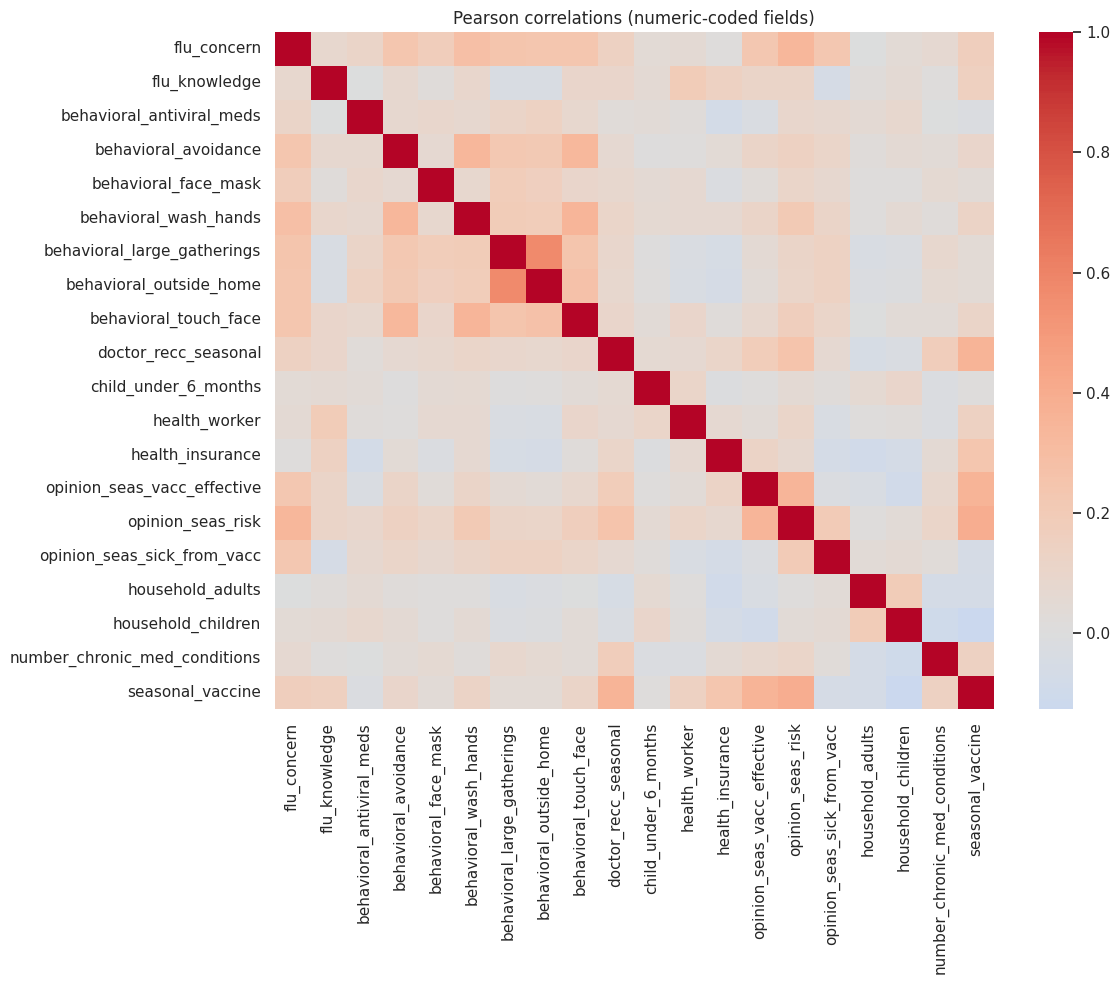

,Pearson r
opinion_seas_risk,0.393312
opinion_seas_vacc_effective,0.357129
doctor_recc_seasonal,0.354831
health_insurance,0.235809
flu_concern,0.163732
flu_knowledge,0.155676
health_worker,0.149263
number_chronic_med_conditions,0.145271
household_children,-0.127039
behavioral_wash_hands,0.120247


Correlations are associations, not causal effects; categorical codes need careful interpretation.


In [11]:
num=train.select_dtypes(include='number').drop(columns='respondent_id',errors='ignore')
corr=num.corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(12,10));sns.heatmap(corr,cmap='coolwarm',center=0,ax=ax)
ax.set_title('Pearson correlations (numeric-coded fields)');plt.tight_layout()
fig.savefig(FIGURES/'06_correlations.png',dpi=140);plt.show()
assoc=corr.seasonal_vaccine.drop('seasonal_vaccine').sort_values(key=abs,ascending=False)
display(assoc.head(15).to_frame('Pearson r'))
print('Correlations are associations, not causal effects; categorical codes need careful interpretation.')

,feature,status,count,acceptance_pct
0,health_insurance,Present,2831,58.67
1,health_insurance,Missing,1925,46.23
2,employment_sector,Present,2442,50.61
3,employment_sector,Missing,2314,56.83
4,income_poverty,Present,3966,54.11
5,income_poverty,Missing,790,51.27
6,doctor_recc_seasonal,Present,4435,54.68
7,doctor_recc_seasonal,Missing,321,39.25


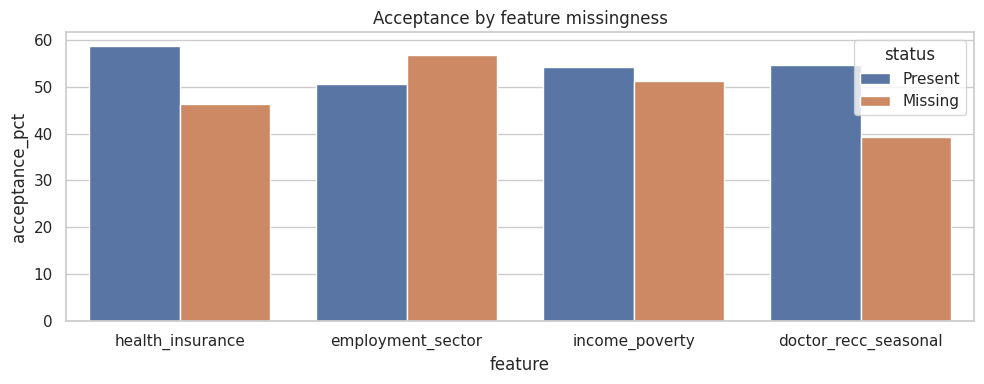

In [12]:
# Are missing values themselves associated with vaccine acceptance?
rows=[]
for col in ['health_insurance','employment_sector','income_poverty','doctor_recc_seasonal']:
    for missing,group in train.groupby(train[col].isna()):
        rows.append({'feature':col,'status':'Missing' if missing else 'Present',
                     'count':len(group),'acceptance_pct':group.seasonal_vaccine.mean()*100})
missing_effect=pd.DataFrame(rows);display(missing_effect.round(2))
fig,ax=plt.subplots(figsize=(10,4));sns.barplot(data=missing_effect,x='feature',y='acceptance_pct',hue='status',ax=ax)
ax.set_title('Acceptance by feature missingness');plt.tight_layout()
fig.savefig(FIGURES/'07_missingness_signal.png',dpi=150);plt.show()

## Page 6 — Shared split and EDA handover
**Interpretation:** Add your own observations from the actual plots. Report effect direction, subgroup counts and limitations. Hospitalisation outcomes are not in this dataset.

In [13]:
from sklearn.model_selection import train_test_split
train_idx,val_idx=train_test_split(train.index,test_size=0.2,stratify=train.seasonal_vaccine,random_state=42)
train_split=train.loc[train_idx].copy();val_split=train.loc[val_idx].copy()
train_split.to_csv(DATA/'train_split.csv',index=False)
val_split.to_csv(DATA/'validation_split.csv',index=False)
train.to_csv(DATA/'full_training.csv',index=False)
test.to_csv(DATA/'test.csv',index=False)
sample.to_csv(DATA/'example_submission.csv',index=False)
miss.to_csv(RESULTS/'eda_missingness.csv');missing_effect.to_csv(RESULTS/'eda_missingness_signal.csv',index=False)
print('Shared files saved to',DATA,' | Train:',len(train_split),'Validation:',len(val_split))

Shared files saved to /content/drive/MyDrive/Hackathon2026/data  | Train: 3804 Validation: 952


### EDA findings — complete after viewing the charts
- **Data quality:** [Describe highest missingness and any train/test differences.]
- **Vaccine acceptance:** [Insert observed percentage and class balance.]
- **Demographic differences:** [Identify groups with higher/lower acceptance; mention sample sizes.]
- **Health/attitude associations:** [Describe patterns without implying causation.]
- **Modelling recommendation:** Use leakage-safe imputation, common split and probability predictions.
- **Limitation:** No hospitalisation outcomes; medical risk assumptions require separate justification.

## Part 2 — Shared model preparation

Use the exact same training/validation respondents for both models. All imputers and encoders are fitted inside each training pipeline, preventing validation leakage.

In [14]:
# Read identical split files created by Notebook 01.
train_df = pd.read_csv(DATA/'train_split.csv')
val_df = pd.read_csv(DATA/'validation_split.csv')
full_df = pd.read_csv(DATA/'full_training.csv')
test_df = pd.read_csv(DATA/'test.csv')
features = [c for c in full_df if c not in ['respondent_id','seasonal_vaccine']]
X_train,y_train = train_df[features],train_df['seasonal_vaccine'].astype(int)
X_val,y_val = val_df[features],val_df['seasonal_vaccine'].astype(int)
X_full,y_full = full_df[features],full_df['seasonal_vaccine'].astype(int)
X_test = test_df[features]
assert list(X_train.columns)==list(X_val.columns)==list(X_test.columns)
print('Train / validation / test:',len(X_train),len(X_val),len(X_test))

Train / validation / test: 3804 952 4749


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.base import clone

# All fitted transforms remain inside the training pipeline: no leakage.
cat_cols=X_train.select_dtypes(include=['object','category','string']).columns.tolist()
num_cols=[c for c in features if c not in cat_cols]
preprocessor=ColumnTransformer([
 ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),
 ('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                         ('encode',OneHotEncoder(handle_unknown='ignore'))]),cat_cols)
])

## Part 3 — Random Forest

Train and evaluate the Random Forest; save its ROC curve, confusion matrix, validation probabilities, and full-training test probabilities.

In [16]:
from sklearn.ensemble import RandomForestClassifier
MODEL_NAME="random_forest"
model=Pipeline([("preprocessor",preprocessor),("classifier",RandomForestClassifier(n_estimators=250,max_depth=14,min_samples_leaf=2,random_state=42,n_jobs=-1))])

,ROC-AUC,F1 (0.5),Precision (0.5),Recall (0.5),Brier score
random_forest,0.8454,0.7856,0.7788,0.7926,0.1629


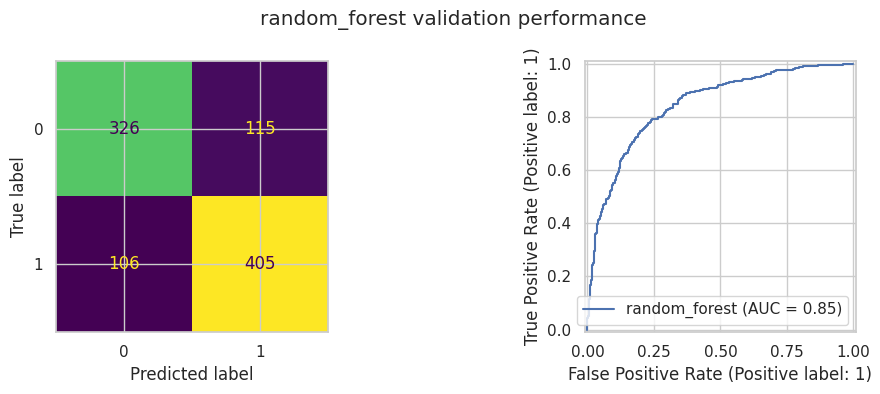

In [17]:
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, brier_score_loss, ConfusionMatrixDisplay, RocCurveDisplay

# Validate using the held-out respondents; never tune on the competition test set.
model.fit(X_train,y_train)
val_prob=model.predict_proba(X_val)[:,1]
val_pred=(val_prob>=0.5).astype(int)
metrics={'ROC-AUC':roc_auc_score(y_val,val_prob), 'F1 (0.5)':f1_score(y_val,val_pred),
         'Precision (0.5)':precision_score(y_val,val_pred,zero_division=0),
         'Recall (0.5)':recall_score(y_val,val_pred,zero_division=0),
         'Brier score':brier_score_loss(y_val,val_prob)}
display(pd.DataFrame([metrics],index=[MODEL_NAME]).round(4))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_val,val_pred,ax=ax[0],colorbar=False)
RocCurveDisplay.from_predictions(y_val,val_prob,ax=ax[1],name=MODEL_NAME)
fig.suptitle(MODEL_NAME+' validation performance')
fig.tight_layout();fig.savefig(FIGURES/(MODEL_NAME+'_validation.png'),dpi=140);plt.show()

In [18]:
# Refit a fresh pipeline on all labelled training rows for the competition test set.
# The validation probabilities above remain out-of-sample for honest comparison.
final_model=clone(model)
final_model.fit(X_full,y_full)
test_prob=final_model.predict_proba(X_test)[:,1]
assert len(val_prob)==len(val_df) and len(test_prob)==len(test_df)
pd.DataFrame({'respondent_id':val_df.respondent_id,'actual':y_val,
              'probability':val_prob}).to_csv(RESULTS/(MODEL_NAME+'_validation.csv'),index=False)
pd.DataFrame({'respondent_id':test_df.respondent_id,
              'probability':test_prob}).to_csv(RESULTS/(MODEL_NAME+'_test.csv'),index=False)
pd.DataFrame([metrics],index=[MODEL_NAME]).to_csv(RESULTS/(MODEL_NAME+'_metrics.csv'))
print('Saved validation, test probabilities and metrics for',MODEL_NAME)

Saved validation, test probabilities and metrics for random_forest


## Part 4 — CatBoost

Train and evaluate CatBoost on the same split, then save its separate output files.

In [19]:
!pip -q install catboost
from catboost import CatBoostClassifier
MODEL_NAME="catboost"
model=Pipeline([("preprocessor",preprocessor),("classifier",CatBoostClassifier(iterations=400,depth=5,learning_rate=0.05,loss_function="Logloss",verbose=False,random_seed=42,thread_count=2))])

,ROC-AUC,F1 (0.5),Precision (0.5),Recall (0.5),Brier score
catboost,0.8506,0.7924,0.8086,0.7769,0.1561


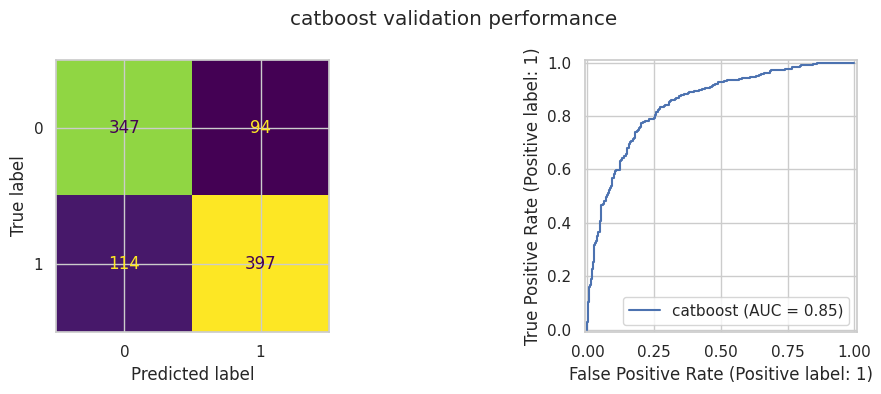

In [20]:
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, brier_score_loss, ConfusionMatrixDisplay, RocCurveDisplay

# Validate using the held-out respondents; never tune on the competition test set.
model.fit(X_train,y_train)
val_prob=model.predict_proba(X_val)[:,1]
val_pred=(val_prob>=0.5).astype(int)
metrics={'ROC-AUC':roc_auc_score(y_val,val_prob), 'F1 (0.5)':f1_score(y_val,val_pred),
         'Precision (0.5)':precision_score(y_val,val_pred,zero_division=0),
         'Recall (0.5)':recall_score(y_val,val_pred,zero_division=0),
         'Brier score':brier_score_loss(y_val,val_prob)}
display(pd.DataFrame([metrics],index=[MODEL_NAME]).round(4))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_val,val_pred,ax=ax[0],colorbar=False)
RocCurveDisplay.from_predictions(y_val,val_prob,ax=ax[1],name=MODEL_NAME)
fig.suptitle(MODEL_NAME+' validation performance')
fig.tight_layout();fig.savefig(FIGURES/(MODEL_NAME+'_validation.png'),dpi=140);plt.show()

In [21]:
# Refit a fresh pipeline on all labelled training rows for the competition test set.
# The validation probabilities above remain out-of-sample for honest comparison.
final_model=clone(model)
final_model.fit(X_full,y_full)
test_prob=final_model.predict_proba(X_test)[:,1]
assert len(val_prob)==len(val_df) and len(test_prob)==len(test_df)
pd.DataFrame({'respondent_id':val_df.respondent_id,'actual':y_val,
              'probability':val_prob}).to_csv(RESULTS/(MODEL_NAME+'_validation.csv'),index=False)
pd.DataFrame({'respondent_id':test_df.respondent_id,
              'probability':test_prob}).to_csv(RESULTS/(MODEL_NAME+'_test.csv'),index=False)
pd.DataFrame([metrics],index=[MODEL_NAME]).to_csv(RESULTS/(MODEL_NAME+'_metrics.csv'))
print('Saved validation, test probabilities and metrics for',MODEL_NAME)

Saved validation, test probabilities and metrics for catboost


## Part 5 — Compare models and visualise results

ROC-AUC measures discrimination (higher is better); Brier score measures probability accuracy (lower is better). These metrics do **not** replace the competition’s expected-cost evaluation.

,ROC-AUC,F1 (0.5),Precision (0.5),Recall (0.5),Brier score
random_forest,0.8454,0.7856,0.7788,0.7926,0.1629
catboost,0.8506,0.7924,0.8086,0.7769,0.1561


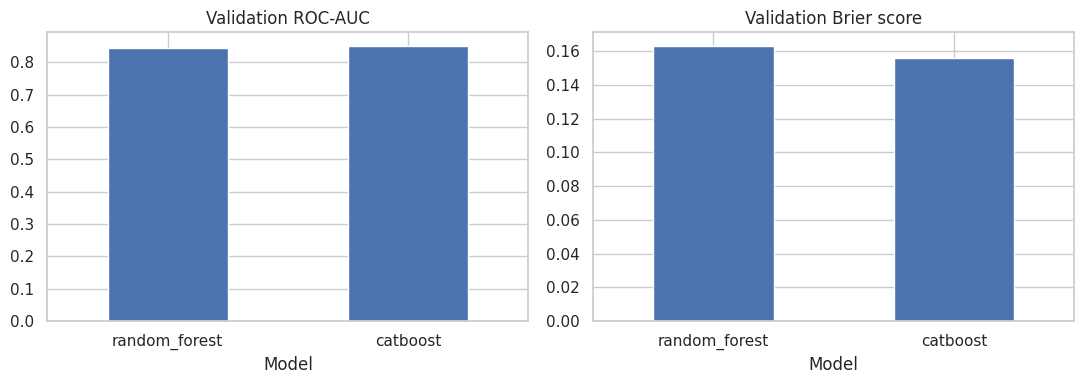

Ensemble ROC-AUC: 0.8515
Ensemble Brier score: 0.157
Saved model comparison and ensemble validation probabilities.


In [22]:
# Read both model outputs that were saved in the previous sections.
rf_metrics = pd.read_csv(RESULTS / 'random_forest_metrics.csv', index_col=0)
cb_metrics = pd.read_csv(RESULTS / 'catboost_metrics.csv', index_col=0)
comparison = pd.concat([rf_metrics, cb_metrics])
display(comparison.round(4))
comparison.to_csv(RESULTS / 'rf_catboost_comparison.csv')

# Visual comparison of discrimination and probability calibration quality.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
comparison['ROC-AUC'].plot(kind='bar', ax=axes[0], title='Validation ROC-AUC')
comparison['Brier score'].plot(kind='bar', ax=axes[1], title='Validation Brier score')
for ax in axes:
    ax.set_xlabel('Model')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / 'rf_catboost_comparison.png', dpi=150)
plt.show()

# Combine held-out predictions by respondent ID, never by row position alone.
rf = pd.read_csv(RESULTS / 'random_forest_validation.csv')
cb = pd.read_csv(RESULTS / 'catboost_validation.csv')
combined = rf.merge(cb, on='respondent_id', suffixes=('_rf', '_cb'), validate='one_to_one')
assert len(combined) == len(val_df), 'Validation IDs are missing or duplicated.'
assert (combined.actual_rf == combined.actual_cb).all(), 'Labels disagree.'
combined['ensemble_probability'] = (combined.probability_rf + combined.probability_cb) / 2
combined.to_csv(RESULTS / 'rf_catboost_validation_comparison.csv', index=False)

from sklearn.metrics import roc_auc_score, brier_score_loss
print('Ensemble ROC-AUC:', round(roc_auc_score(combined.actual_rf, combined.ensemble_probability), 4))
print('Ensemble Brier score:', round(brier_score_loss(combined.actual_rf, combined.ensemble_probability), 4))
print('Saved model comparison and ensemble validation probabilities.')

### Findings and interpretation (complete after running)

- **EDA:** Describe the largest missing-value patterns and whether train/test distributions look similar.
- **Vaccine acceptance:** Explain the largest observed differences by age, recommendation, attitudes and chronic conditions, including subgroup sample sizes.
- **Random Forest:** Record validation ROC-AUC, Brier score, and false positives/negatives.
- **CatBoost:** Record the same metrics and compare with Random Forest.
- **Ensemble:** Report whether averaging improves held-out probability quality.
- **Cost objective:** Explain that final ranking still requires documented hospitalisation risk and vaccination/compensation costs.

Avoid claiming medical causality or a model winner before checking outputs.